In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import warnings
from tensorflow.keras import datasets, layers, models
warnings.filterwarnings('ignore')

In [2]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras import layers, models, callbacks

In [3]:
df=pd.read_csv('Survey_extended_new1.csv')

In [4]:
df.head()

,Unnamed: 0,age,Total Optimism,Total Mastery,Total positive affect,Total negative affect,tlifesat,tpstress,Total Self esteem,Total social desirability,Total PCOISS
0,0,24.0,22.0,22.0,49.0,39.0,23.0,29.0,34.0,4.0,51.0
1,1,39.0,19.0,21.0,35.0,35.0,30.0,22.0,27.0,5.0,40.0
2,2,48.0,19.0,19.0,74.0,14.0,33.0,19.0,24.0,8.0,47.0
3,3,41.0,26.0,26.0,49.0,36.0,33.0,31.0,29.0,3.0,63.0
4,4,23.0,18.0,23.0,85.0,11.0,16.0,27.0,29.0,4.0,46.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Unnamed: 0                 398 non-null    int64  
 1   age                        398 non-null    float64
 2   Total Optimism             398 non-null    float64
 3   Total Mastery              398 non-null    float64
 4   Total positive affect      398 non-null    float64
 5   Total negative affect      398 non-null    float64
 6   tlifesat                   398 non-null    float64
 7   tpstress                   398 non-null    float64
 8   Total Self esteem          398 non-null    float64
 9   Total social desirability  398 non-null    float64
 10  Total PCOISS               398 non-null    float64
dtypes: float64(10), int64(1)
memory usage: 34.3 KB


In [6]:
df=df[['age', 'Total Optimism', 'Total Mastery',
       'Total positive affect', 'Total negative affect', 'tlifesat',
       'tpstress', 'Total Self esteem', 'Total social desirability',
       'Total PCOISS']]

In [7]:
df.isnull().sum()

age                          0
Total Optimism               0
Total Mastery                0
Total positive affect        0
Total negative affect        0
tlifesat                     0
tpstress                     0
Total Self esteem            0
Total social desirability    0
Total PCOISS                 0
dtype: int64

In [8]:
y=df['tpstress']
X=df.drop('tpstress', axis=1)

In [9]:
X.head()

,age,Total Optimism,Total Mastery,Total positive affect,Total negative affect,tlifesat,Total Self esteem,Total social desirability,Total PCOISS
0,24.0,22.0,22.0,49.0,39.0,23.0,34.0,4.0,51.0
1,39.0,19.0,21.0,35.0,35.0,30.0,27.0,5.0,40.0
2,48.0,19.0,19.0,74.0,14.0,33.0,24.0,8.0,47.0
3,41.0,26.0,26.0,49.0,36.0,33.0,29.0,3.0,63.0
4,23.0,18.0,23.0,85.0,11.0,16.0,29.0,4.0,46.0


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
# Initialize and fit scaler on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaler to the test data
X_test_scaled = scaler.transform(X_test)

In [13]:
# Linear regression
# Initialize the Linear Regression Mode
model= LinearRegression()

#  Train the Model
model.fit(X_train_scaled, y_train)

#  Make Predictions
y_pred = model.predict(X_test_scaled)

In [14]:
#  Evaluate the Model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("R-squared (R2 Score):", r2)

Mean Squared Error (MSE): 14.324035801161273
R-squared (R2 Score): 0.6164772388207715


# FCNN

In [15]:
import tensorflow as tf

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras import layers, models, callbacks

In [30]:
from tensorflow.keras.optimizers import Adam

In [52]:
# Deeper model

odel_FCNN = models.Sequential([
    # لایه اول: استخراج ویژگی‌های اولیه
    layers.Dense(64, activation='relu', input_shape=(9,)),
    layers.BatchNormalization(),
    
    # لایه دوم: کاهش ابعاد برای فشرده‌سازی الگوها
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    
    # لایه سوم: استخراج ویژگی‌های نهایی با Dropout بسیار ملایم
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.1),
    
    # لایه چهارم: آماده‌سازی نهایی
    layers.Dense(16, activation='relu'),
    
    # لایه خروجی: پیش‌بینی رگرسیون
    layers.Dense(1)
])


model_FCNN.compile(
    optimizer=Adam(learning_rate=0.0007),
    loss='mean_squared_error'
)

In [53]:
# Define early stopping callback
early_stopping = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_FCNN = model_FCNN.fit(X_train_scaled, y_train, epochs=300, batch_size=32,
                    validation_data=(X_test_scaled, y_test),
                    callbacks=[early_stopping])

Epoch 1/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 6.0786 - val_loss: 17.4072
Epoch 2/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 5.7176 - val_loss: 16.9684
Epoch 3/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 5.6263 - val_loss: 17.3175
Epoch 4/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 5.6913 - val_loss: 17.0891
Epoch 5/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 5.5483 - val_loss: 17.1200
Epoch 6/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 5.5192 - val_loss: 17.6753
Epoch 7/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 5.5040 - val_loss: 17.1068
Epoch 8/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 5.4473 - val_loss: 17.8538
Epoch 9/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 5.4558 - val_loss: 17.1433
Epoch 10/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 5.6307 - val_loss: 17.3743
Epoch 11/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 5.5732 - val_loss: 17.7154
Epoch 12/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0

In [54]:
# Evaluate the model on the validation set
y_pred_FCNN = model_FCNN.predict(X_test_scaled).flatten()  # Flatten the predictions to a 1D array

# Test
mse_FCNN = mean_squared_error(y_test, y_pred_FCNN)
print(f'Mean squared Error (MAE): {mse_FCNN:.4f}')

# Compute R-squared (R²)
r2_FCNN = r2_score(y_test, y_pred_FCNN)
print(f'R-squared (R²): {r2_FCNN:.4f}')

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
Mean squared Error (MAE): 16.9684
R-squared (R²): 0.5457


In [59]:
from sklearn.metrics import mean_absolute_error
model_FCNN = models.Sequential([
    layers.Dense(128, activation='relu', input_shape=(9,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)  # Linear output for regression
])

model_FCNN.compile(optimizer='adam', loss='mean_squared_error')

# Early stopping for Keras
early_stopping = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Fit the model
history_FCNN = model_FCNN.fit(
    X_train_scaled, y_train,
    epochs=300,
    batch_size=32,
    validation_data=(X_test_scaled, y_test),
    callbacks=[early_stopping],
    verbose=0
)

# Evaluate Keras model
y_pred_keras = model_FCNN.predict(X_test_scaled).flatten()
mae_keras = mean_absolute_error(y_test, y_pred_keras)
mse_keras = mean_squared_error(y_test, y_pred_keras)
r2_keras = r2_score(y_test, y_pred_keras)
print(f"Original FCNN -> MAE: {mae_keras:.4f}, MSE: {mse_keras:.4f}, R²: {r2_keras:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
Original FCNN -> MAE: 3.4092, MSE: 18.7540, R²: 0.4979


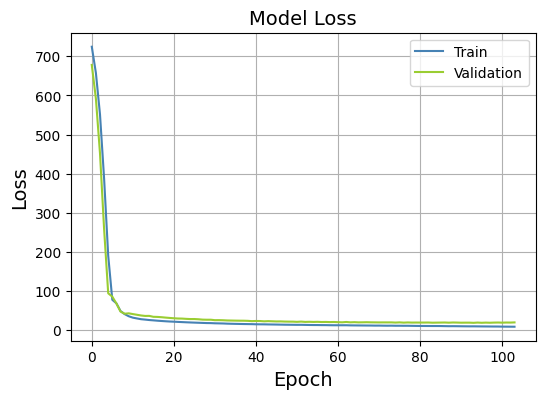

In [62]:
# Plot training & validation loss values
history = history_FCNN
plt.figure(figsize=(6, 4))
plt.plot(history.history['loss'], color='steelblue', label='Train')
plt.plot(history.history['val_loss'], color='yellowgreen', label='Validation')
plt.title('Model Loss', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=14)
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


# CNN

In [27]:
# Reshape the input data for compatibility with CNN
X_train_CNN = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_CNN = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

In [28]:
X_train_CNN

array([[[ 0.26400538],
        [ 1.04268396],
        [-0.1413545 ],
        ...,
        [-0.25846078],
        [-1.13869764],
        [ 0.23426702]],

       [[-1.40144245],
        [-1.95120768],
        [ 1.6987339 ],
        ...,
        [-0.05674373],
        [-1.13869764],
        [-1.92025989]],

       [[-1.09863375],
        [ 0.79319299],
        [-0.62328242],
        ...,
        [-0.22178495],
        [-1.13869764],
        [ 0.48286627]],

       ...,

       [[-0.11450549],
        [ 0.04472008],
        [-0.4480359 ],
        ...,
        [-0.1484333 ],
        [ 1.81726848],
        [ 0.06853418]],

       [[-0.03880332],
        [ 1.29217493],
        [ 1.47967576],
        ...,
        [-0.07508164],
        [ 1.81726848],
        [ 0.31713343]],

       [[ 0.4911119 ],
        [ 0.54370202],
        [ 1.47967576],
        ...,
        [-0.11175747],
        [ 0.33928542],
        [ 0.06853418]]], shape=(318, 9, 1))

In [33]:
# Build the CNN model
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(32, kernel_size=3, activation='relu', input_shape=(X_train_CNN.shape[1], X_train_CNN.shape[2])),
    tf.keras.layers.MaxPooling1D(pool_size=2),
    tf.keras.layers.Conv1D(64, kernel_size=3, activation='relu'),
    #tf.keras.layers.MaxPooli ng1D(pool_size=2),
    tf.keras.layers.Flatten(),
    #tf.keras.layers.Dropout(0.5),  # Adding Dropout layer
    tf.keras.layers.Dense(128, activation='relu'), # , kernel_regularizer=l2(0.001)
    #tf.keras.layers.Dropout(0.5),  # Adding Dropout layer
    tf.keras.layers.Dense(1)  # Output layer with 1 neuron for regression
])
# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

In [34]:
# Define early stopping callback
early_stopping = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train the model with early stopping
history = model.fit(X_train_CNN, y_train, epochs=100, batch_size=32,
                    validation_data=(X_test_CNN, y_test),
                    callbacks=[early_stopping])

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 484.8972 - val_loss: 443.9940
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 409.6929 - val_loss: 334.5258
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 259.5372 - val_loss: 161.3381
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 96.2359 - val_loss: 100.0639
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 74.1933 - val_loss: 99.2283
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 55.4228 - val_loss: 70.2828
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 48.8089 - val_loss: 62.6220
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 40.5436 - val_loss: 61.7770
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 37.7188 - val_loss: 54.9608
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 34.4962 - val_loss: 49.3222
Epoch 11/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 32.3876 - val_loss: 46.0554
Epoch 12/100
10/10 ━━━━━━━

In [35]:
y_pred_CNN = model.predict(X_test_CNN).flatten()  # Flatten the predictions to a 1D array

# Test Accuracy
mae_CNN = mean_squared_error(y_test, y_pred_CNN)
print(f'Mean Absolute Error (MAE): {mae_CNN:.4f}')

r2_CNN = r2_score(y_test, y_pred_CNN)
print(f'R-squared (R²): {r2_CNN:.4f}')

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Mean Absolute Error (MAE): 14.6801
R-squared (R²): 0.4598


# RNN

We have 

X_train_scaled → shape (n_samples, features)

X_test_scaled → shape (n_samples, features)


RNNs expect 3D input:

(samples, timesteps, features)

Each numerical feature is treated as a “time step”


In [63]:
X_train_RNN = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_test_RNN  = X_test_scaled.reshape((X_test_scaled.shape[0], X_train_scaled.shape[1], 1))


In [64]:
X_train_RNN.shape

(318, 9, 1)

In [65]:
# Build the RNN model
model = tf.keras.models.Sequential([
    tf.keras.layers.SimpleRNN(64, activation='relu', input_shape=(X_train_RNN.shape[1], 1)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)  # Output layer with 1 neuron for regression
])

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

In [66]:
# Define early stopping callback
early_stopping = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# model.fit(X_trainrnn, y_trainrnn, batch_size=32, epochs=10, validation_data=(X_testrnn, y_testrnn))
history = model.fit(X_train_RNN, y_train, epochs=100, batch_size=32,
                    validation_split=0.2,
                    callbacks=[early_stopping])

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 487.8984 - val_loss: 511.3436
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 450.5891 - val_loss: 435.5973
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 297.1216 - val_loss: 113.3476
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 91.7594 - val_loss: 64.1421
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 56.1526 - val_loss: 69.0265
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 48.8762 - val_loss: 57.2582
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 40.1327 - val_loss: 54.7194
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 38.3577 - val_loss: 48.0467
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 33.7180 - val_loss: 46.0542
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 31.7290 - val_loss: 41.0541
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 27.9002 - val_loss: 38.7085
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/st

In [67]:
# Evaluate the model on the validation set
y_pred_RNN = model.predict(X_test_RNN).flatten()  # Flatten the predictions to a 1D array

# Compute Mean Absolute Error (MAE)
mae_RNN = mean_squared_error(y_test, y_pred_RNN)
print(f'Mean Absolute Error (MAE): {mae_RNN:.4f}')

# Compute R-squared (R²)
r2_RNN = r2_score(y_test, y_pred_RNN)
print(f'R-squared (R²): {r2_RNN:.4f}')

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Mean Absolute Error (MAE): 14.6508
R-squared (R²): 0.4609


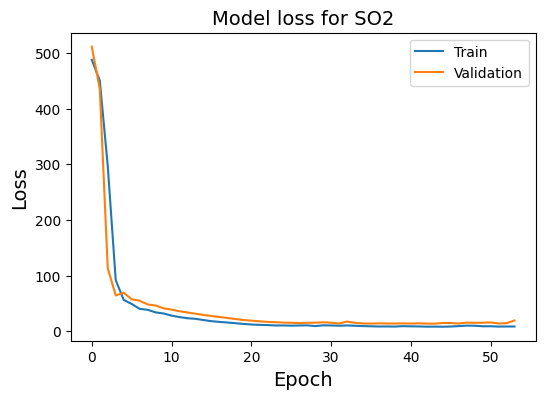

In [68]:
# Plot training & validation loss values
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss for SO2', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=14)
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

# GRU




In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense

In [69]:
# Reshape the input data for GRU model
X_train_GRU = np.reshape(X_train, (X_train.shape[0], 1, X_train.shape[1]))
X_test_GRU = np.reshape(X_test, (X_test.shape[0], 1, X_test.shape[1]))

This is the correct way to feed tabular data into a GRU if you still want to use GRU.

✔️ No time steps

✔️ All 10 features go into the GRU at once

✔️ The GRU acts similarly to a Dense layer with gating

Your GRU will now behave consistently and you will no longer get shape mismatches.

In [48]:
# Define the GRU model
model = Sequential([
    GRU(64, input_shape=(X_train_GRU.shape[1], X_train_GRU.shape[2]), return_sequences=True),
    Dense(1)  # Output layer for regression
])
# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

In [70]:
#Deeper Model 1
model = Sequential([
    GRU(128, input_shape=(X_train_GRU.shape[1], X_train_GRU.shape[2]), return_sequences=True),
    GRU(64, return_sequences=False),
    Dense(64, activation='relu'),
    Dense(1)  # Output layer for regression
])
model.compile(optimizer='adam', loss='mean_squared_error')

In [ ]:
#Deeper model 2
from tensorflow.keras.layers import GRU, Dense, Dropout

# Define the improved GRU model
model = Sequential()
model.add(GRU(128, input_shape=(X_train_GRU.shape[1], X_train_GRU.shape[2]), return_sequences=True))
model.add(Dropout(0.2))
model.add(GRU(64))
model.add(Dropout(0.1))
model.add(Dense(32, activation='relu'))
model.add(Dense(1))  # Output layer for regression

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

In [71]:
# Define early stopping callback
early_stopping = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# Train the model with early stopping
history = model.fit(X_train_GRU, y_train, epochs=100, batch_size=32,
                    validation_split=0.2,
                    callbacks=[early_stopping])

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 465.9196 - val_loss: 452.7482
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 374.6344 - val_loss: 348.2691
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 264.6756 - val_loss: 218.9094
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 145.4791 - val_loss: 104.9023
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 58.9388 - val_loss: 41.6332
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 22.0123 - val_loss: 21.4012
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 18.1084 - val_loss: 20.9174
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 20.2919 - val_loss: 20.8295
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 18.6434 - val_loss: 20.1728
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 17.4877 - val_loss: 21.1367
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 17.1585 - val_loss: 21.5555
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10m

In [72]:
# Make predictions
predictions = model.predict(X_test_GRU)
predictions_test = predictions.reshape(predictions.shape[0])
# Compute Mean Absolute Error (MAE)
mae_GRU = mean_squared_error(y_test, predictions_test)
print(f'Mean Absolute Error (MAE): {mae_GRU:.4f}')

# Compute R-squared (R²)
r2_GRU = r2_score(y_test, predictions_test)
print(f'R-squared (R²): {r2_GRU:.4f}')# Make predictions on the test data

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step
Mean Absolute Error (MAE): 16.1087
R-squared (R²): 0.4073


In [73]:
# Make predictions
predictions = model.predict(X_train_GRU)
predictions_train = predictions.reshape(predictions.shape[0])
# Compute Mean Absolute Error (MAE)
mae_GRU_train = mean_squared_error(y_train, predictions_train)
print(f'Mean Absolute Error (MAE): {mae_GRU_train:.4f}')

# Compute R-squared (R²)
r2_GRU_train = r2_score(y_train, predictions_train)
print(f'R-squared (R²): {r2_GRU_train:.4f}')# Make predictions on the test data

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Mean Absolute Error (MAE): 10.5838
R-squared (R²): 0.4078


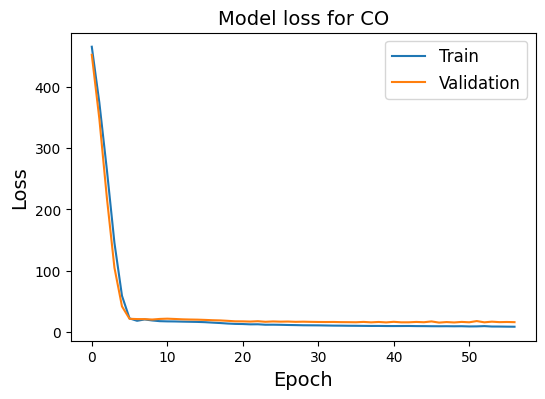

In [74]:
# Plot training & validation loss values
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss for CO', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=14)
plt.legend(['Train', 'Validation'], loc='upper right', fontsize=12)
#plt.savefig('PM25.png', dpi=300, bbox_inches='tight')
plt.show()

# LSTM

In [75]:
from tensorflow.keras.layers import LSTM, Dense

In [76]:
X_train_LSTM = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_LSTM = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

print("LSTM input shape:", X_train_LSTM.shape)

LSTM input shape: (318, 1, 9)


In [77]:
model = Sequential()
model.add(LSTM(64, activation='tanh', return_sequences=False,
               input_shape=(1, X_train.shape[1])))
model.add(Dense(32, activation='relu'))
model.add(Dense(1))     # regression output

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          18,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_28 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,057 (82.25 KB)

 Trainable params: 21,057 (82.25 KB)

 Non-trainable params: 0 (0.00 B)

In [78]:
history = model.fit(
    X_train_LSTM, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 499.7852 - val_loss: 535.2751
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 494.3173 - val_loss: 528.8296
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 488.1573 - val_loss: 521.4419
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 481.1382 - val_loss: 512.2890
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 472.4817 - val_loss: 501.0028
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 461.5343 - val_loss: 487.1356
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 448.1908 - val_loss: 469.7690
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 431.7516 - val_loss: 448.5137
Epoch 9/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 412.0450 - val_loss: 423.2943
Epoch 10/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 388.3704 - val_loss: 395.1013
Epoch 11/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 363.8490 - val_loss: 363.5461
Epoch 12/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9

In [79]:
pred_test = model.predict(X_test_LSTM).reshape(-1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


In [81]:
mae_LSTM = mean_squared_error(y_test, pred_test)
r2_LSTM = r2_score(y_test, pred_test)

print(f"MAE  (LSTM): {mae_LSTM:.4f}")
print(f"R²   (LSTM): {r2_LSTM:.4f}")

MAE  (LSTM): 23.4940
R²   (LSTM): 0.1355


In [82]:
# Define early stopping callback
early_stopping = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# Train the model with early stopping
history = model.fit(X_train_LSTM, y_train, epochs=100, batch_size=32,
                    validation_split=0.2,
                    callbacks=[early_stopping])

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 11.6672 - val_loss: 20.3706
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 11.2647 - val_loss: 19.7749
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 10.9033 - val_loss: 19.2206
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 10.5679 - val_loss: 18.7638
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 10.2686 - val_loss: 18.3745
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 10.0551 - val_loss: 18.0755
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 9.8273 - val_loss: 17.6859
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.5955 - val_loss: 17.4419
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.4295 - val_loss: 17.2769
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 9.2934 - val_loss: 17.0627
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.1604 - val_loss: 16.8477
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 9

In [83]:
pred_test = model.predict(X_test_LSTM).reshape(-1)
mae_LSTM = mean_squared_error(y_test, pred_test)
r2_LSTM = r2_score(y_test, pred_test)

print(f"MAE  (LSTM): {mae_LSTM:.4f}")
print(f"R²   (LSTM): {r2_LSTM:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
MAE  (LSTM): 18.2453
R²   (LSTM): 0.3287


# LSTM + GRU hybrid

In [84]:
X_train_seq = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_seq  = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

print("Hybrid model input shape:", X_train_seq.shape)


Hybrid model input shape: (318, 1, 9)


In [85]:
model = Sequential()

# LSTM layer
model.add(LSTM(64, activation='tanh', return_sequences=True,
               input_shape=(1, X_train.shape[1])))
model.add(Dropout(0.2))

# GRU layer
model.add(GRU(32, activation='tanh'))
model.add(Dropout(0.2))
# Dense layers
model.add(Dense(32, activation='relu'))
model.add(Dense(1))   # regression output

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 1, 64)               │          18,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 1, 64)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_12 (GRU)                         │ (None, 32)                  │           9,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_29 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_30 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,441 (115.00 KB)

 Trainable params: 29,441 (115.00 KB)

 Non-trainable params: 0 (0.00 B)

In [86]:
# -----------------------------------------------------------
history = model.fit(
    X_train_seq, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 502.0104 - val_loss: 539.6191
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 497.8853 - val_loss: 534.6999
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 492.6261 - val_loss: 528.2579
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 485.5951 - val_loss: 519.4000
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 475.7556 - val_loss: 506.7992
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 461.9536 - val_loss: 488.0677
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 441.2294 - val_loss: 460.2025
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 410.9137 - val_loss: 419.3911
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 367.2238 - val_loss: 363.0002
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 310.9016 - val_loss: 293.0066
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 241.1896 - val_loss: 215.2364
Epoch 12/100
8/8 ━━━━━━━━━━━━━

In [88]:
pred_test = model.predict(X_test_seq).reshape(-1)

# -----------------------------------------------------------
# 7) METRICS
# -----------------------------------------------------------
mae = mean_squared_error(y_test, pred_test)
r2 = r2_score(y_test, pred_test)

print(f"MAE (LSTM+GRU): {mae:.4f}")
print(f"R²  (LSTM+GRU): {r2:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
MAE (LSTM+GRU): 15.3819
R²  (LSTM+GRU): 0.4340


# CNN+RNN

In [89]:
X_train_seq = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_seq  = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

In [91]:
model = Sequential()

# LSTM layer
model.add(LSTM(64, activation='tanh', return_sequences=True,
               input_shape=(1, X_train.shape[1])))
model.add(Dropout(0.2))

# GRU layer
model.add(GRU(32, activation='tanh'))
model.add(Dropout(0.2))

# Dense layers
model.add(Dense(32, activation='relu'))
model.add(Dense(1))   # regression output

model.compile(optimizer='adam', loss='mse')
model.summary()


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                        │ (None, 1, 64)               │          18,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 1, 64)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_14 (GRU)                         │ (None, 32)                  │           9,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_31 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_32 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,441 (115.00 KB)

 Trainable params: 29,441 (115.00 KB)

 Non-trainable params: 0 (0.00 B)

In [92]:
history = model.fit(
    X_train_seq, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - loss: 502.6803 - val_loss: 540.6124
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 498.4869 - val_loss: 535.7375
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 493.0456 - val_loss: 529.0898
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 484.9445 - val_loss: 519.8893
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 474.3310 - val_loss: 506.6405
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 459.2864 - val_loss: 487.3110
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 436.5319 - val_loss: 458.9430
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 404.5318 - val_loss: 417.3811
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 358.6002 - val_loss: 359.5925
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 298.1808 - val_loss: 284.7605
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 222.0403 - val_loss: 199.0333
Epoch 12/100
8/8 ━━━━━━━━━━━━━

In [94]:


pred_test = model.predict(X_test_seq).reshape(-1)

# -----------------------------------------------------------
# 7) METRICS
# -----------------------------------------------------------
mae = mean_squared_error(y_test, pred_test)
r2 = r2_score(y_test, pred_test)

print(f"MAE (LSTM+GRU): {mae:.4f}")
print(f"R²  (LSTM+GRU): {r2:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
MAE (LSTM+GRU): 15.2833
R²  (LSTM+GRU): 0.4376


# CNN+GRU

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
X_train_seq = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_seq  = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

print("CNN+GRU model input shape:", X_train_seq.shape)

In [96]:
model = Sequential()

# CNN layers
model.add(Conv1D(filters=64, kernel_size=1, activation='relu', input_shape=(1, X_train.shape[1])))
model.add(MaxPooling1D(pool_size=1))
model.add(Dropout(0.2))

# GRU layer
model.add(GRU(32, activation='tanh'))
model.add(Dropout(0.2))

# Dense layers
model.add(Dense(32, activation='relu'))
model.add(Dense(1))   # regression output

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)                    │ (None, 1, 64)               │             640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 1, 64)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 1, 64)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_15 (GRU)                         │ (None, 32)                  │           9,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_33 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_34 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,137 (43.50 KB)

 Trainable params: 11,137 (43.50 KB)

 Non-trainable params: 0 (0.00 B)

In [97]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# -----------------------------------------------------------
# 6) TRAIN MODEL
# -----------------------------------------------------------
history = model.fit(
    X_train_seq, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 490.7428 - val_loss: 522.7480
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 474.7626 - val_loss: 502.6044
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 452.1729 - val_loss: 474.3824
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 423.7178 - val_loss: 435.1935
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 379.9318 - val_loss: 382.6146
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 325.1070 - val_loss: 316.3492
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 261.0074 - val_loss: 240.8501
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 191.8790 - val_loss: 164.7168
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 119.6878 - val_loss: 99.0929
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 69.0149 - val_loss: 53.3819
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 38.1576 - val_loss: 30.8122
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━━━

In [99]:
# -----------------------------------------------------------
# 8) PREDICT
# -----------------------------------------------------------
pred_test = model.predict(X_test_seq).reshape(-1)

# -----------------------------------------------------------
# 9) METRICS
# -----------------------------------------------------------
mae = mean_squared_error(y_test, pred_test)
r2 = r2_score(y_test, pred_test)

print(f"MAE (CNN+GRU): {mae:.4f}")
print(f"R²  (CNN+GRU): {r2:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
MAE (CNN+GRU): 16.7490
R²  (CNN+GRU): 0.3837


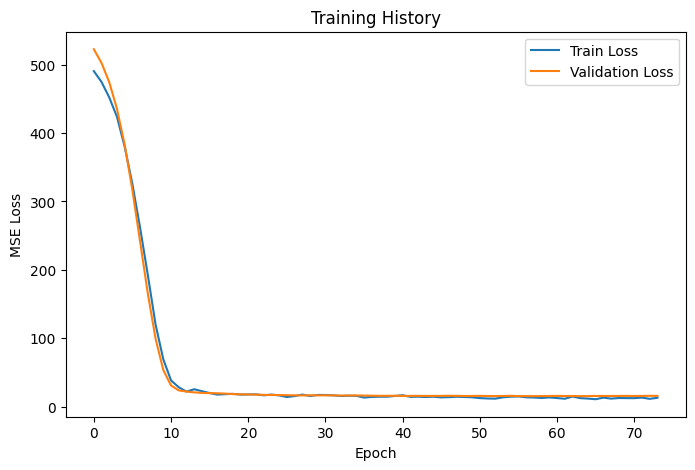

In [100]:
# -----------------------------------------------------------
# 7) PLOT TRAINING HISTORY
# -----------------------------------------------------------
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training History')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()




In [101]:
import numpy as np
import pandas as pd

# -----------------------------
# 1) PARAMETERS
# -----------------------------
num_samples = 2000       # number of sequences
time_steps = 8           # 8 timesteps (e.g., 8 days)
num_features = 10        # features: CO, O3, NO2, SO2, PM10, Temperature, DewPoint, Humidity, WindSpeed, Pressure

feature_names = [
    'CO', 'O3', 'NO2', 'SO2', 'PM10', 
    'Temperature°C', 'DewPoint°C', 'Humidity', 'WindSpeedkmh', 'PressurehPa'
]

# -----------------------------
# 2) GENERATE SYNTHETIC DATA
# -----------------------------
np.random.seed(42)

X = np.zeros((num_samples, time_steps, num_features))
y = np.zeros((num_samples, time_steps))  # time-dependent PM2.5

for i in range(num_samples):
    # Base values for weather & pollutants
    temp_base = np.random.uniform(10, 35)  # °C
    humidity_base = np.random.uniform(30, 90)  # %
    pressure_base = np.random.uniform(990, 1030)  # hPa
    wind_base = np.random.uniform(0, 20)  # km/h
    pollutant_base = np.random.uniform(5, 80, size=5)  # CO, O3, NO2, SO2, PM10
    
    for t in range(time_steps):
        # Add some daily variations and random noise
        X[i, t, 0:5] = pollutant_base + np.random.normal(0, 5, size=5)  # pollutants
        X[i, t, 5] = temp_base + np.random.normal(0, 2)                   # Temperature
        X[i, t, 6] = temp_base - np.random.uniform(1, 5)                  # DewPoint
        X[i, t, 7] = humidity_base + np.random.normal(0, 5)               # Humidity
        X[i, t, 8] = wind_base + np.random.normal(0, 2)                   # Wind
        X[i, t, 9] = pressure_base + np.random.normal(0, 2)               # Pressure
        
        # PM2.5 depends on pollutants and weather at this timestep + noise
        y[i, t] = (0.5*X[i, t, 4] + 0.2*X[i, t, 2] + 0.1*X[i, t, 0] 
                   + 0.1*X[i, t, 1] - 0.05*X[i, t, 7] + np.random.normal(0, 2))

# -----------------------------
# 3) SAVE TO CSV
# -----------------------------
# Flatten the 3D array to 2D for CSV
data_list = []
for i in range(num_samples):
    for t in range(time_steps):
        row = X[i, t].tolist() + [y[i, t], i, t]  # add PM2.5, sample_id, timestep
        data_list.append(row)

columns = feature_names + ['PM2.5', 'SampleID', 'Timestep']
df_synthetic = pd.DataFrame(data_list, columns=columns)

# Save CSV
df_synthetic.to_csv('synthetic_PM25_timeseries_full.csv', index=False)
print("Synthetic dataset saved as 'synthetic_PM25_timeseries_full.csv'")


Synthetic dataset saved as 'synthetic_PM25_timeseries_full.csv'
